In [5]:
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.wcs import WCS
import matplotlib.pyplot as plt
%matplotlib inline
from astropy.stats import mad_std, sigma_clipped_stats
import astropy.units as u

In [2]:
# unzips the zip files on Jupyter so the data can be accessed.

# import zipfile

# with zipfile.ZipFile("20250125.zip", "r") as zip_ref:
#   zip_ref.extractall("20250125")

In [6]:
with fits.open('20241016/KP.20241016.37537.98_L1.fits') as hdul:
    hdul.info()

Filename: 20241016/KP.20241016.37537.98_L1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1024   ()      
  1  RECEIPT       1 BinTableHDU     31   24R x 11C   [26A, 7A, 9A, 1A, 18A, 140A, 53A, 40A, 3A, 40A, 4A]   
  2  CONFIG        1 BinTableHDU     13   0R x 2C   [D, D]   
  3  TELEMETRY     1 BinTableHDU     24   131R x 6C   [11A, 11A, 8A, 8A, 14A, 67A]   
  4  GREEN_SCI_FLUX1    1 ImageHDU        13   (4080, 35)   float64   
  5  GREEN_SCI_FLUX2    1 ImageHDU        13   (4080, 35)   float64   
  6  GREEN_SCI_FLUX3    1 ImageHDU        13   (4080, 35)   float64   
  7  GREEN_SKY_FLUX    1 ImageHDU        13   (4080, 35)   float64   
  8  GREEN_CAL_FLUX    1 ImageHDU        13   (4080, 35)   float64   
  9  GREEN_SCI_VAR1    1 ImageHDU         8   (4080, 35)   float64   
 10  GREEN_SCI_VAR2    1 ImageHDU         8   (4080, 35)   float64   
 11  GREEN_SCI_VAR3    1 ImageHDU         8   (4080, 35)   float64   
 12  GREEN_SKY_VAR 

In [7]:
with fits.open('20250125/KP.20250125.17314.15_L1.fits') as hdul:
    hdul.info()

Filename: 20250125/KP.20250125.17314.15_L1.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1027   ()      
  1  RECEIPT       1 BinTableHDU     31   24R x 11C   [26A, 7A, 9A, 1A, 18A, 140A, 53A, 40A, 3A, 40A, 4A]   
  2  CONFIG        1 BinTableHDU     13   0R x 2C   [D, D]   
  3  TELEMETRY     1 BinTableHDU     24   125R x 6C   [11A, 11A, 8A, 8A, 14A, 67A]   
  4  GREEN_SCI_FLUX1    1 ImageHDU        13   (4080, 35)   float64   
  5  GREEN_SCI_FLUX2    1 ImageHDU        13   (4080, 35)   float64   
  6  GREEN_SCI_FLUX3    1 ImageHDU        13   (4080, 35)   float64   
  7  GREEN_SKY_FLUX    1 ImageHDU        13   (4080, 35)   float64   
  8  GREEN_CAL_FLUX    1 ImageHDU        13   (4080, 35)   float64   
  9  GREEN_SCI_VAR1    1 ImageHDU         8   (4080, 35)   float64   
 10  GREEN_SCI_VAR2    1 ImageHDU         8   (4080, 35)   float64   
 11  GREEN_SCI_VAR3    1 ImageHDU         8   (4080, 35)   float64   
 12  GREEN_SKY_VAR 

In [66]:
for fname in ["20241016/KP.20241016.37537.98_L1.fits", "20250125/KP.20250125.17314.15_L1.fits"]:
    with fits.open(fname) as hdul:
        hdr = hdul[0].header
        print(fname)
        print("  OBJECT :", hdr.get("OBJECT"))
        print("  IMTYPE :", hdr.get("IMTYPE"))
        print("  SCISEL :", hdr.get("SCISEL"))  # Shows what light source fed the SCI fiber

20241016/KP.20241016.37537.98_L1.fits
  OBJECT : IRAS 04125+2902
  IMTYPE : Object
  SCISEL : open
20250125/KP.20250125.17314.15_L1.fits
  OBJECT : IRAS 04125+2902
  IMTYPE : Object
  SCISEL : open


[False False False ...  True  True  True]


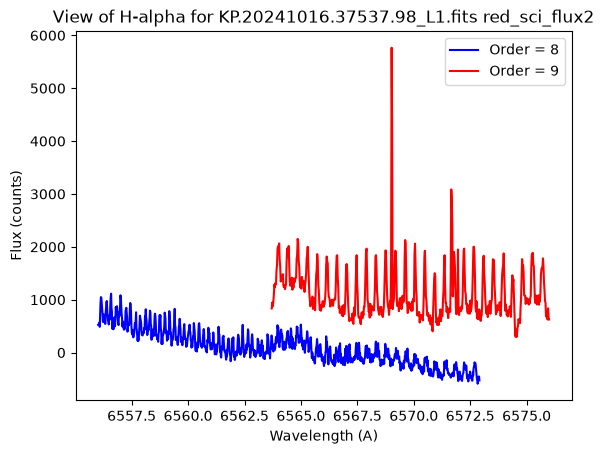

In [71]:
with fits.open('20241016/KP.20241016.37537.98_L1.fits') as hdul:
    green_sci_flux1 = hdul['GREEN_SCI_FLUX1'].data
    green_sci_wave1 = hdul['GREEN_SCI_WAVE1'].data
    green_sci_flux2 = hdul['GREEN_SCI_FLUX2'].data
    green_sci_wave2 = hdul['GREEN_SCI_WAVE2'].data
    green_sky_flux = hdul['GREEN_SKY_FLUX'].data
    green_sky_wave = hdul['GREEN_SKY_WAVE'].data
    red_sci_flux1 = hdul['RED_SCI_FLUX1'].data
    red_sci_wave1 = hdul['RED_SCI_WAVE1'].data
    red_sci_flux2 = hdul['RED_SCI_FLUX2'].data
    red_sci_wave2 = hdul['RED_SCI_WAVE2'].data
    red_sky_flux = hdul['RED_SKY_FLUX'].data
    red_sky_wave = hdul['RED_SKY_WAVE'].data


# plt.plot(green_sci_wave1, green_sci_flux1)
# plt.xlabel('Wavelength')
# plt.ylabel('Flux')
# plt.title('Full Green Flux#1 over Full Green Wavelength#1')
# plt.show()


# plt.plot(green_sci_wave1[0], green_sci_flux1[0])
# plt.xlabel('Wavelength')
# plt.ylabel('Flux')
# plt.title('Index 0, Green Flux#1 over Green Wavelength#1')
# plt.show()



# plt.plot(red_sci_wave1, red_sci_flux1)
# plt.xlabel('Wavelength')
# plt.ylabel('Flux')
# plt.title('Full Red Flux#1 over Full Red Wavelength#1')
# plt.show()

#the grraph for flux1 is super weird. Flux2 looks much better here.

#looks ar order 8
red_sci_wave1_Halpha1 = red_sci_wave2[8]
red_sci_flux1_Halpha1 = red_sci_flux2[8]

mask1 = (red_sci_wave1_Halpha1 >= 6556) & (red_sci_wave1_Halpha1 <= 6576)

#looks at order 9
red_sci_wave1_Halpha2 = red_sci_wave2[9]
red_sci_flux1_Halpha2 = red_sci_flux2[9]

mask2 = (red_sci_wave1_Halpha2 >= 6556) & (red_sci_wave1_Halpha2 <= 6576)
print(mask)

plt.plot(red_sci_wave1_Halpha1[mask1], red_sci_flux1_Halpha1[mask1], color='blue', label='Order = 8')
plt.plot(red_sci_wave1_Halpha2[mask2], red_sci_flux1_Halpha2[mask2], color='red', label='Order = 9')
plt.xlabel('Wavelength (A)')
plt.ylabel('Flux (counts)')
plt.title('View of H-alpha for KP.20241016.37537.98_L1.fits red_sci_flux2')
plt.legend()
plt.show()

[False False False ...  True  True  True]


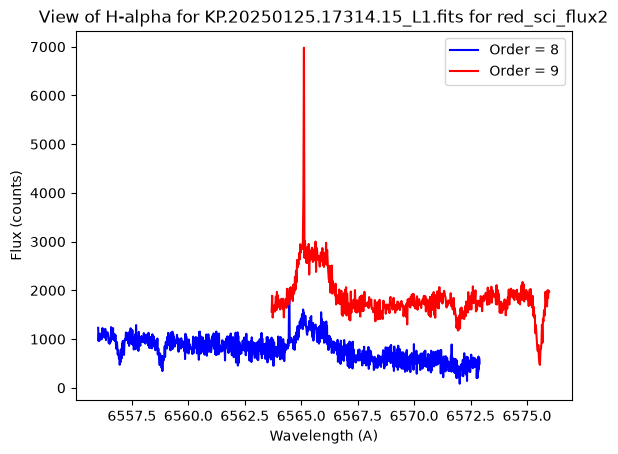

In [72]:
with fits.open('20250125/KP.20250125.17314.15_L1.fits') as hdul:
    green_sci_flux1 = hdul['GREEN_SCI_FLUX1'].data
    green_sci_wave1 = hdul['GREEN_SCI_WAVE1'].data
    green_sky_flux = hdul['GREEN_SKY_FLUX'].data
    green_sky_wave = hdul['GREEN_SKY_WAVE'].data
    red_sci_flux1 = hdul['RED_SCI_FLUX1'].data
    red_sci_wave1 = hdul['RED_SCI_WAVE1'].data
    red_sci_flux2 = hdul['RED_SCI_FLUX2'].data
    red_sci_wave2 = hdul['RED_SCI_WAVE2'].data
    red_sky_flux = hdul['RED_SKY_FLUX'].data
    red_sky_wave = hdul['RED_SKY_WAVE'].data


# plt.plot(green_sci_wave1, green_sci_flux1)
# plt.xlabel('Wavelength')
# plt.ylabel('Flux')
# plt.title('Full Green Flux#1 over Full Green Wavelength#1')
# plt.show()


# plt.plot(green_sci_wave1[0], green_sci_flux1[0])
# plt.xlabel('Wavelength')
# plt.ylabel('Flux')
# plt.title('Index 0, Green Flux#1 over Green Wavelength#1')
# plt.show()



# plt.plot(red_sci_wave1, red_sci_flux1)
# plt.xlabel('Wavelength')
# plt.ylabel('Flux')
# plt.title('Full Red Flux#1 over Full Red Wavelength#1')
# plt.show()


#both flux 1 and 2 look good here.

#looks ar order 8
red_sci_wave1_Halpha1 = red_sci_wave2[8]
red_sci_flux1_Halpha1 = red_sci_flux2[8]

mask1 = (red_sci_wave1_Halpha1 >= 6556) & (red_sci_wave1_Halpha1 <= 6576)

#looks at order 9
red_sci_wave1_Halpha2 = red_sci_wave2[9]
red_sci_flux1_Halpha2 = red_sci_flux2[9]

mask2 = (red_sci_wave1_Halpha2 >= 6556) & (red_sci_wave1_Halpha2 <= 6576)
print(mask)

plt.plot(red_sci_wave1_Halpha1[mask1], red_sci_flux1_Halpha1[mask1], color='blue', label='Order = 8')
plt.plot(red_sci_wave1_Halpha2[mask2], red_sci_flux1_Halpha2[mask2], color='red', label='Order = 9')
plt.xlabel('Wavelength (A)')
plt.ylabel('Flux (counts)')
plt.title('View of H-alpha for KP.20250125.17314.15_L1.fits for red_sci_flux2')
plt.legend()
plt.show()

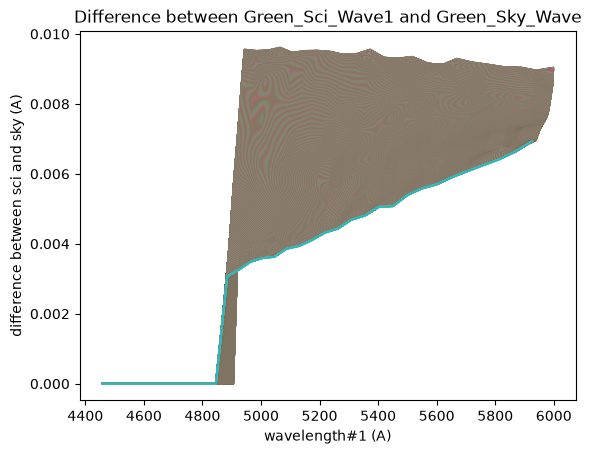

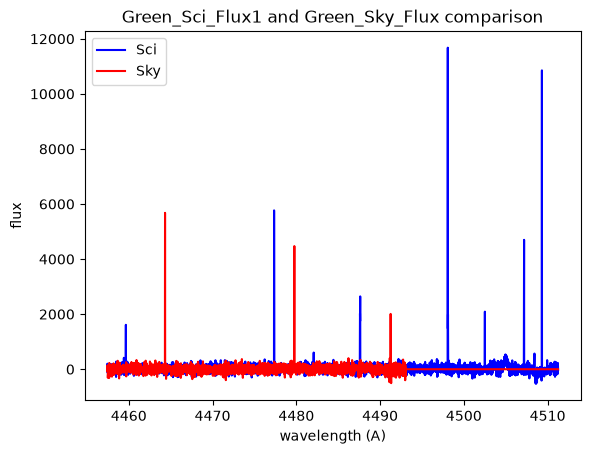

In [43]:


green_wave1_sky_difference= green_sci_wave1 - green_sky_wave

plt.plot(green_sci_wave1, green_wave1_sky_difference)
plt.xlabel('wavelength#1 (A)')
plt.ylabel('difference between sci and sky (A)')
plt.title('Difference between Green_Sci_Wave1 and Green_Sky_Wave')
plt.show()

#there is no difference between sci and sky for the 4400 A to 4800 A

# plt.plot(green_sci_wave1[34], green_wave1_sky_difference[34])
# plt.show()

#This means the sky vs sci flux can be graphed in this regime without having to worry about shifts due to sci/sky wave differences.
plt.plot(green_sci_wave1[0], green_sci_flux1[0], color='blue', label='Sci')
plt.plot(green_sky_wave[0], green_sky_flux[0], color='red', label='Sky')
plt.xlabel('wavelength (A)')
plt.ylabel('flux')
plt.title('Green_Sci_Flux1 and Green_Sky_Flux comparison')
plt.legend()
plt.show()

#Sky isn't measured as far as Sci is, and you can see the distinct peaks for both.
